# 04 — Phase 4: Phát hiện bất thường

Phase 4 — Phát hiện bất thường (`scripts/anomaly.py`).

Giờ ban ngày, đặc trưng: công suất/kW, bức xạ, nhiệt độ module, tỉ số công suất/bức xạ. Isolation Forest + One-Class SVM, mỗi mô hình gắn cờ 5% số giờ. **Không có nhãn đúng/sai nên không báo % accuracy** — đánh giá bằng case study (sự cố đã biết) và lời giải thích vật lý.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thư mục gốc của repo (notebook nằm trong notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Repo root:", ROOT)
print("Python:", sys.executable)

Repo root: /home/hatch/workspace/data-mining-project/repo
Python: /home/hatch/workspace/data-mining-project/.venv/bin/python


In [2]:
# Chạy script tương ứng (dùng đúng Python của kernel này)
import subprocess
r = subprocess.run([sys.executable, str(ROOT / "scripts" / "anomaly.py")],
                   capture_output=True, text=True)
print(r.stdout[-3000:])
print(r.stderr[-1000:] if r.returncode else "OK, exit 0")
assert r.returncode == 0, "script chạy lỗi, xem stderr ở trên"

System 4: IF 187 giờ (5.01%), OC-SVM 185 giờ (4.95%), cả 2 cùng gắn cờ 88 giờ, đồng thuận 94.8%, case study: {'label': 'giờ bức xạ > 800 W/m² nhưng công suất < 10% định mức (Phase 1)', 'n_low_power_high_irr_hours': 28, 'if_flagged_of_those': 28, 'ocsvm_flagged_of_those': 24, 'both_flagged_of_those': 24}
System 1278: IF 200 giờ (5.01%), OC-SVM 204 giờ (5.11%), cả 2 cùng gắn cờ 128 giờ, đồng thuận 96.3%, case study: {'label': 'file thô chỉ 68/96 dòng 15 phút, thiếu nhiều', 'date': '2015-07-03', 'daytime_hours_in_analysis': 12, 'if_flagged': 3, 'ocsvm_flagged': 5, 'both_flagged': 2}
System 1403: IF 191 giờ (5.0%), OC-SVM 191 giờ (5.0%), cả 2 cùng gắn cờ 118 giờ, đồng thuận 96.2%, case study: {'label': 'inverter 1 = 0 cả ngày, inverter 2 bình thường', 'date': '2015-06-15', 'daytime_hours_in_analysis': 12, 'if_flagged': 7, 'ocsvm_flagged': 5, 'both_flagged': 4}
Report: outputs/anomaly_report.json

OK, exit 0


## 1. Hai mô hình có đồng ý với nhau không?

In [3]:
import json
rep = json.load(open(ROOT / "outputs/anomaly_report.json"))
for r in rep:
    print(f"System {r['system_id']}: IF {r['if_anomalies']} giờ, "
          f"OC-SVM {r['ocsvm_anomalies']} giờ, cả 2 cùng gắn cờ {r['both_anomalies']} giờ, "
          f"đồng thuận {r['agreement_if_ocsvm_pct']:.1f}%")

System 4: IF 187 giờ, OC-SVM 185 giờ, cả 2 cùng gắn cờ 88 giờ, đồng thuận 94.8%
System 1278: IF 200 giờ, OC-SVM 204 giờ, cả 2 cùng gắn cờ 128 giờ, đồng thuận 96.3%
System 1403: IF 191 giờ, OC-SVM 191 giờ, cả 2 cùng gắn cờ 118 giờ, đồng thuận 96.2%


## 2. Case study: giờ bức xạ cao mà công suất thấp (System 4, 28 giờ)

In [4]:
a4 = pd.read_csv(ROOT / "outputs/anomaly_system_4.csv",
                   parse_dates=["timestamp"])
low = a4[(a4["poa_irradiance_wm2"] > 800) & (a4["power_per_kw"] < 100)]
print("Số giờ bức xạ > 800 mà công suất < 100 W/kW:", len(low))
print("IF gắn cờ (if_score < 0):", (low["if_score"] < 0).sum(), "/", len(low))
low.sort_values("timestamp").head(10)

Số giờ bức xạ > 800 mà công suất < 100 W/kW: 28
IF gắn cờ (if_score < 0): 28 / 28


,timestamp,ac_power_w,power_per_kw,poa_irradiance_wm2,ambient_temp_c,module_temp_c,irr_ratio,if_score,ocsvm_anomaly,outlier_iqr,outlier_low_power_high_irr
23,2015-01-22 09:00:00,5.188215,5.188215,935.185460,-2.526455,3.374940,0.005548,-0.096661,True,True,True
7,2015-01-22 10:00:00,24.340136,24.340136,1139.018517,-0.191749,33.564678,0.021369,-0.124402,True,True,True
20,2015-02-17 09:00:00,0.841935,0.841935,884.443870,-1.994599,28.493834,0.000952,-0.101915,True,True,True
13,2015-02-17 10:00:00,5.981830,5.981830,1063.351520,-1.297453,22.523047,0.005625,-0.111774,True,True,True
10,2015-02-17 11:00:00,14.379339,14.379339,1165.577900,-0.565159,21.880676,0.012337,-0.116746,True,True,True
9,2015-02-17 12:00:00,25.736904,25.736904,1181.696395,-0.041579,24.840490,0.021780,-0.120355,True,True,True
12,2015-02-17 13:00:00,52.695272,52.695272,1081.204733,-0.025456,28.133820,0.048738,-0.113181,True,True,True
16,2015-02-23 12:00:00,18.030688,18.030688,1099.970442,-8.736777,16.124345,0.016392,-0.107561,True,True,True
25,2015-02-23 13:00:00,14.479139,14.479139,910.440610,-8.057470,25.647760,0.015903,-0.094939,False,True,True
19,2015-02-23 14:00:00,19.572222,19.572222,1005.474815,-7.612310,27.771456,0.019466,-0.104830,True,True,True


## 3. Case study: inverter 1 = 0 cả ngày 15/06/2015 (System 1403)

In [5]:
a1403 = pd.read_csv(ROOT / "outputs/anomaly_system_1403.csv",
                     parse_dates=["timestamp"])
day = a1403[a1403["timestamp"].dt.strftime("%Y-%m-%d") == "2015-06-15"]
print("Giờ ban ngày 15/06:", len(day), "| IF gắn cờ:", (day["if_score"] < 0).sum(),
      "| OC-SVM gắn cờ:", day["ocsvm_anomaly"].sum())
day[["timestamp", "ac_power_w", "poa_irradiance_wm2", "power_per_kw",
     "if_score", "ocsvm_anomaly"]]

Giờ ban ngày 15/06: 7 | IF gắn cờ: 7 | OC-SVM gắn cờ: 4


,timestamp,ac_power_w,poa_irradiance_wm2,power_per_kw,if_score,ocsvm_anomaly
51,2015-06-15 12:00:00,2253.364433,933.330325,375.560739,-0.044450,True
55,2015-06-15 11:00:00,2131.399015,884.320460,355.233169,-0.042994,True
62,2015-06-15 13:00:00,2160.593983,887.727203,360.098997,-0.040305,True
97,2015-06-15 10:00:00,1991.835750,815.122790,331.972625,-0.027170,True
105,2015-06-15 14:00:00,1889.828333,763.375758,314.971389,-0.025526,False
137,2015-06-15 09:00:00,1619.409067,652.193933,269.901511,-0.010999,False
153,2015-06-15 15:00:00,1532.226500,609.801982,255.371083,-0.008621,False


## 4. Biểu đồ: giờ bất thường (chấm đỏ) so với giờ bình thường

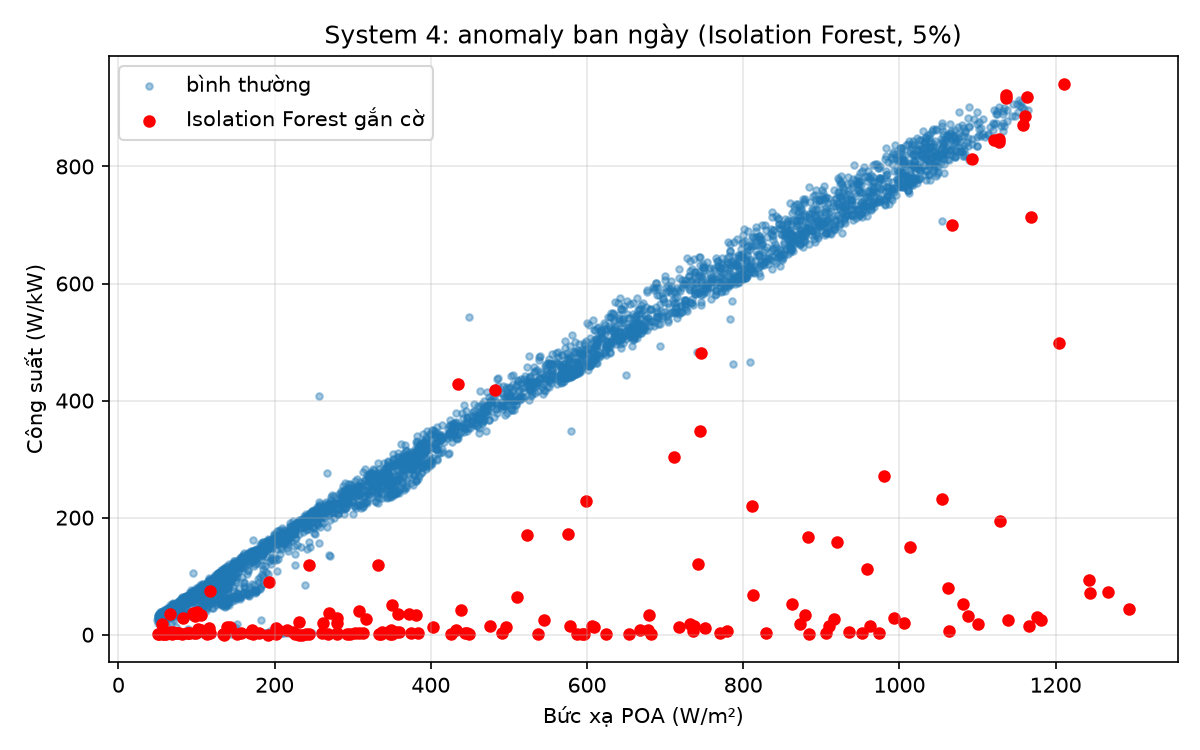

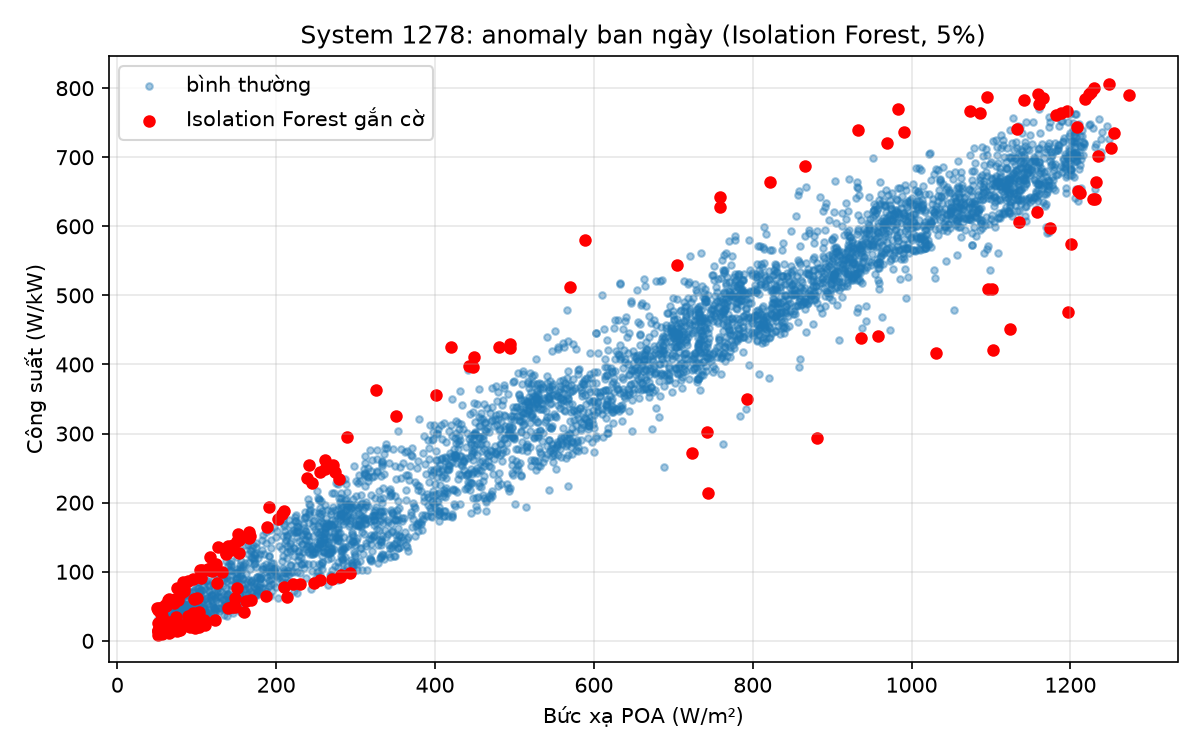

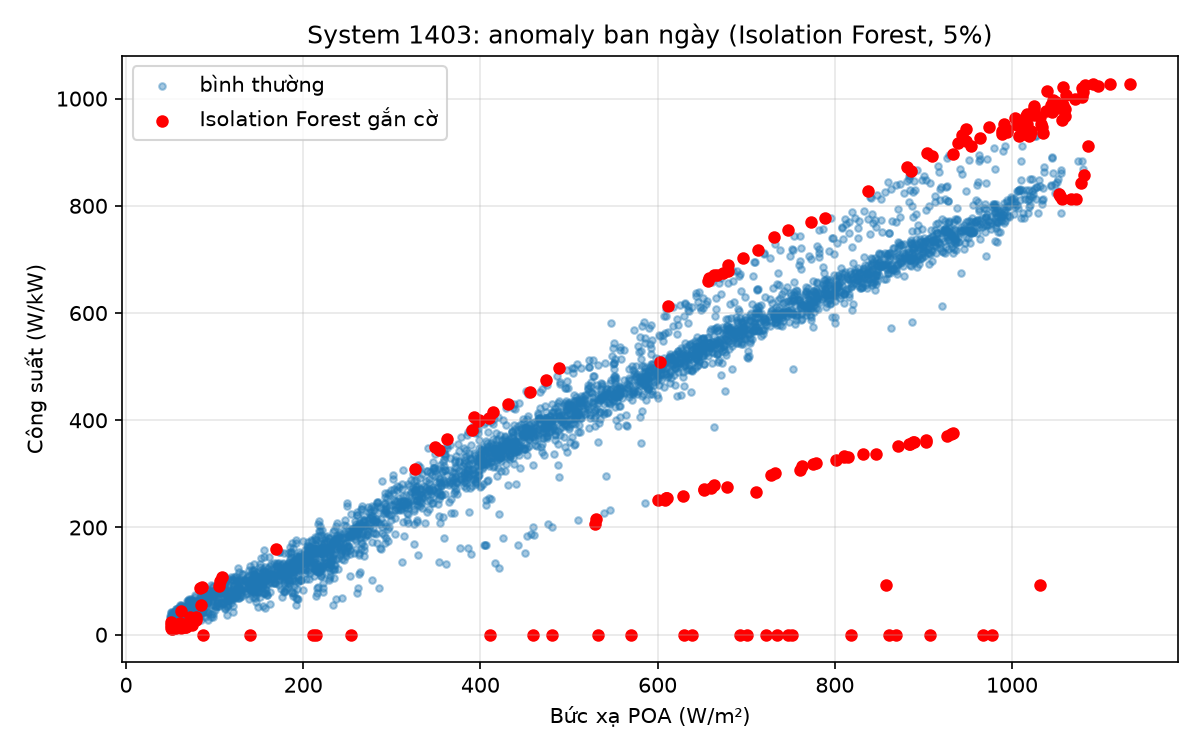

In [6]:
from IPython.display import Image, display
for sid in [4, 1278, 1403]:
    display(Image(filename=str(ROOT / f"outputs/anomaly_system_{sid}.png"),
                  width=900))

**Đọc biểu đồ:** System 4 có cả một dải chấm đỏ sát đáy (bức xạ cao, công suất ≈ 0). System 1403 có 3 dải đỏ: tỉ số cao bất thường (trên), nửa công suất do chết 1 inverter (giữa), mất phát hoàn toàn 05–06/11 (đáy). IF cũng gắn cờ giờ tỉ số cao lúc bình minh — đó chưa chắc là lỗi, cần xem xét vật lý trước khi kết luận.